## Importing Libraries

In [70]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler
import warnings
warnings.filterwarnings('ignore')

**Added device functionality so that when large data becomes available we can smoothly switch to GPU**

In [71]:
device = torch.device("cpu")
print("device:", device)

device: cpu


## Downloading data from Yahoo Finance

In [72]:
import yfinance as yf

def fetch_data(ticker):
    stock_data = yf.Ticker(ticker)
    history = stock_data.history("10y")
    history.index = history.index.date
    return history

ticker = "TSLA"
tesla_data = fetch_data(ticker)
tesla_data.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
2016-10-24,13.400000,13.596667,13.350000,13.517333,41274000,0.0,0.0
2016-10-25,13.526667,13.646000,13.413333,13.489333,36675000,0.0,0.0
2016-10-26,13.400000,13.546000,13.340000,13.482667,84492000,0.0,0.0
2016-10-27,14.089333,14.246667,13.443333,13.600667,196405500,0.0,0.0
2016-10-28,13.600000,13.688000,13.322000,13.331333,64201500,0.0,0.0


## Exploratory Data Analysis

In [73]:
tesla_data.info()

<class 'pandas.DataFrame'>
Index: 2514 entries, 2016-10-24 to 2026-10-23
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Open          2514 non-null   float64
 1   High          2514 non-null   float64
 2   Low           2514 non-null   float64
 3   Close         2514 non-null   float64
 4   Volume        2514 non-null   int64  
 5   Dividends     2514 non-null   float64
 6   Stock Splits  2514 non-null   float64
dtypes: float64(6), int64(1)
memory usage: 157.1+ KB


In [74]:
tesla_data.describe()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
count,2514.000000,2514.000000,2514.000000,2514.000000,2.514000e+03,2514.0,2514.000000
mean,180.041079,183.871687,176.007614,180.013165,1.141037e+08,0.0,0.003182
std,139.500053,142.288494,136.497221,139.407256,7.307554e+07,0.0,0.116273
min,12.073333,12.315333,11.799333,11.931333,1.839300e+07,0.0,0.000000
25%,22.730000,23.144666,22.324667,22.738000,6.932828e+07,0.0,0.000000
50%,195.320000,199.296669,190.646667,195.086662,9.545880e+07,0.0,0.000000
75%,282.411667,286.852501,275.207489,282.413338,1.314645e+08,0.0,0.000000
max,489.880005,498.829987,485.329987,489.880005,9.140820e+08,0.0,5.000000


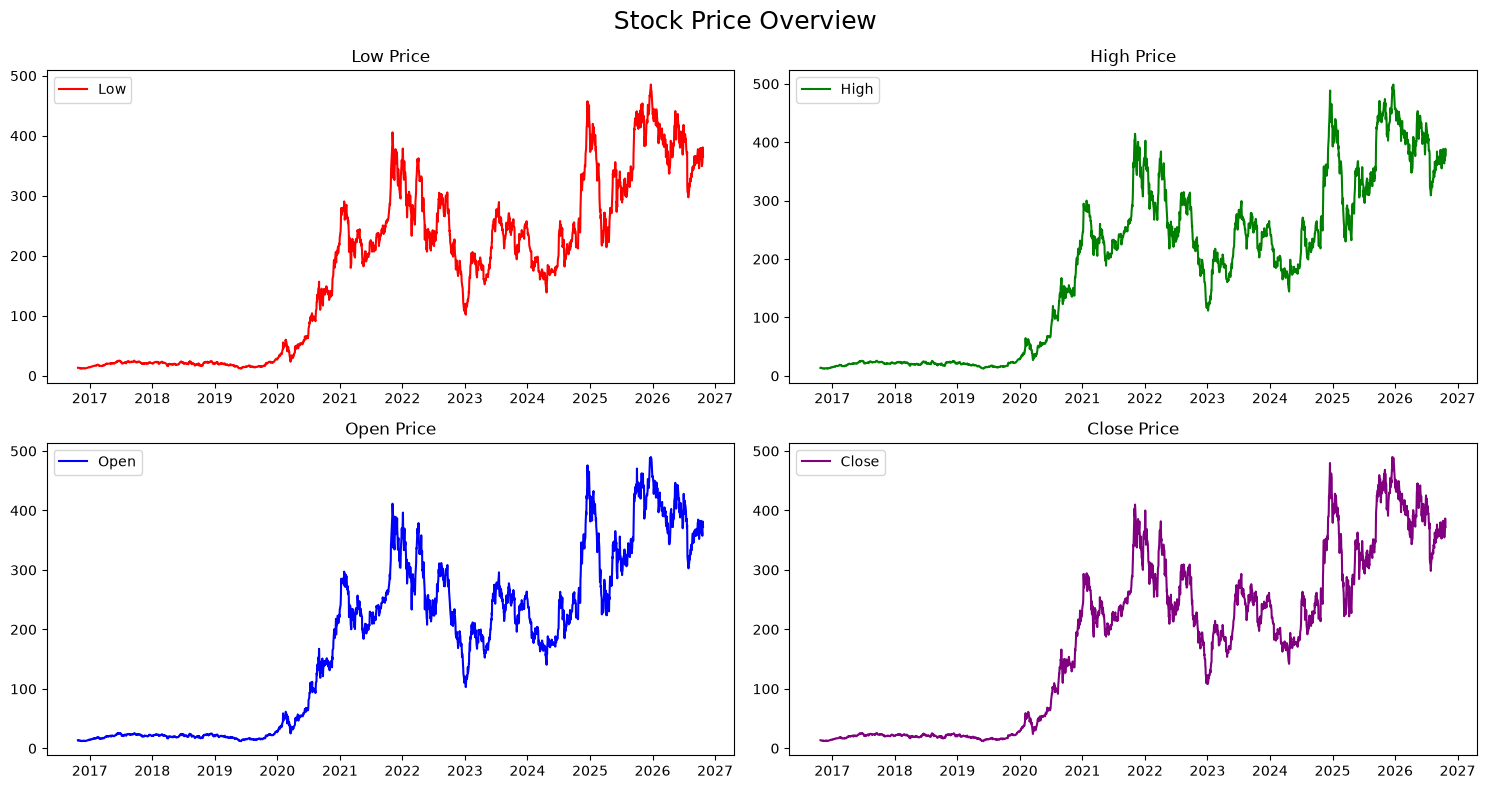

In [75]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 8))
fig.suptitle('Stock Price Overview', fontsize=18)
tesla_data[['Low']].plot(ax=axes[0, 0], title='Low Price', color='red')
tesla_data[['High']].plot(ax=axes[0, 1], title='High Price', color='green')
tesla_data[['Open']].plot(ax=axes[1, 0], title='Open Price', color='blue')
tesla_data[['Close']].plot(ax=axes[1, 1], title='Close Price', color='purple')
plt.tight_layout()
plt.savefig('../images/1.stock_price_overview.png', bbox_inches='tight')
plt.show()

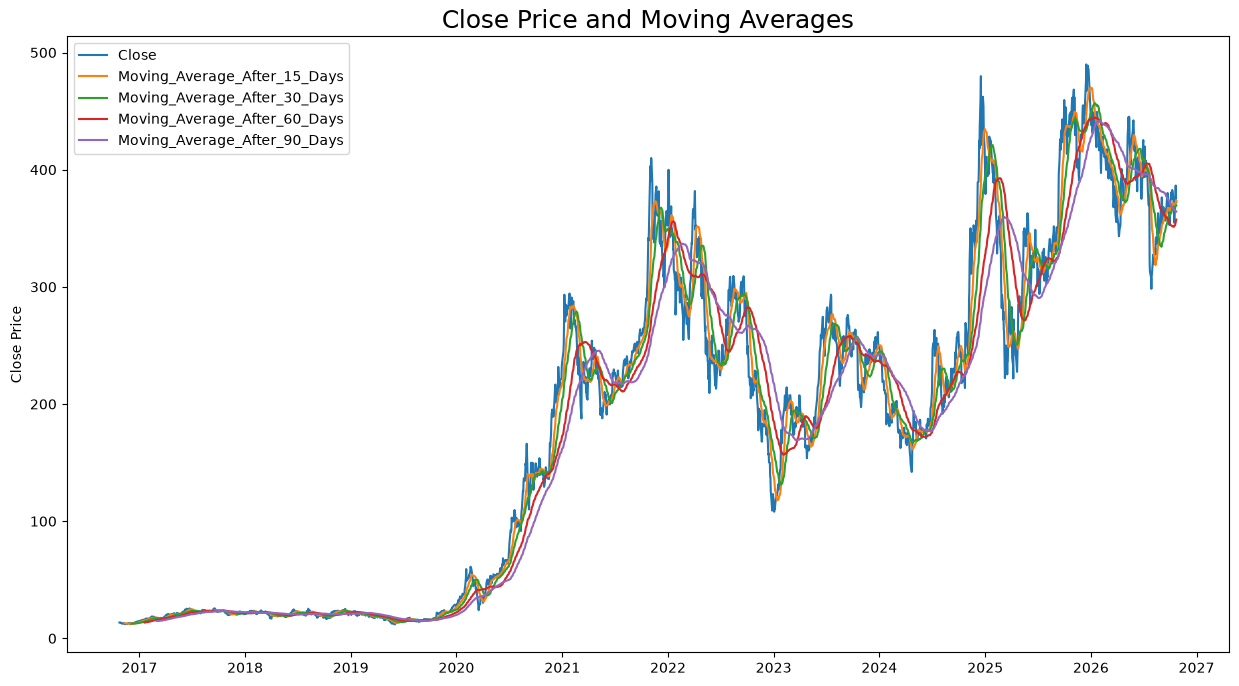

In [76]:
# calculate moving averages for different time periods
window_sizes = [15, 30, 60, 90]

for days in window_sizes:
    column_name = f"Moving_Average_After_{days}_Days"
    tesla_data[column_name] = tesla_data['Close'].rolling(days).mean()


tesla_data[['Close', 'Moving_Average_After_15_Days', 'Moving_Average_After_30_Days', 'Moving_Average_After_60_Days', 'Moving_Average_After_90_Days']].plot(figsize=(15, 8))
plt.title('Close Price and Moving Averages', fontsize=18)
plt.ylabel('Close Price')
plt.savefig('../images/2.close_price_and_moving_average.png', bbox_inches='tight')
plt.show()

In [77]:
# calculates the percentage change in closing price from the previous day
tesla_data['Daily Return'] = tesla_data['Close'].pct_change()
tesla_data['Daily Return'].describe()

count    2513.000000
mean        0.002021
std         0.037535
min        -0.210628
25%        -0.017630
50%         0.001301
75%         0.020488
max         0.226900
Name: Daily Return, dtype: float64

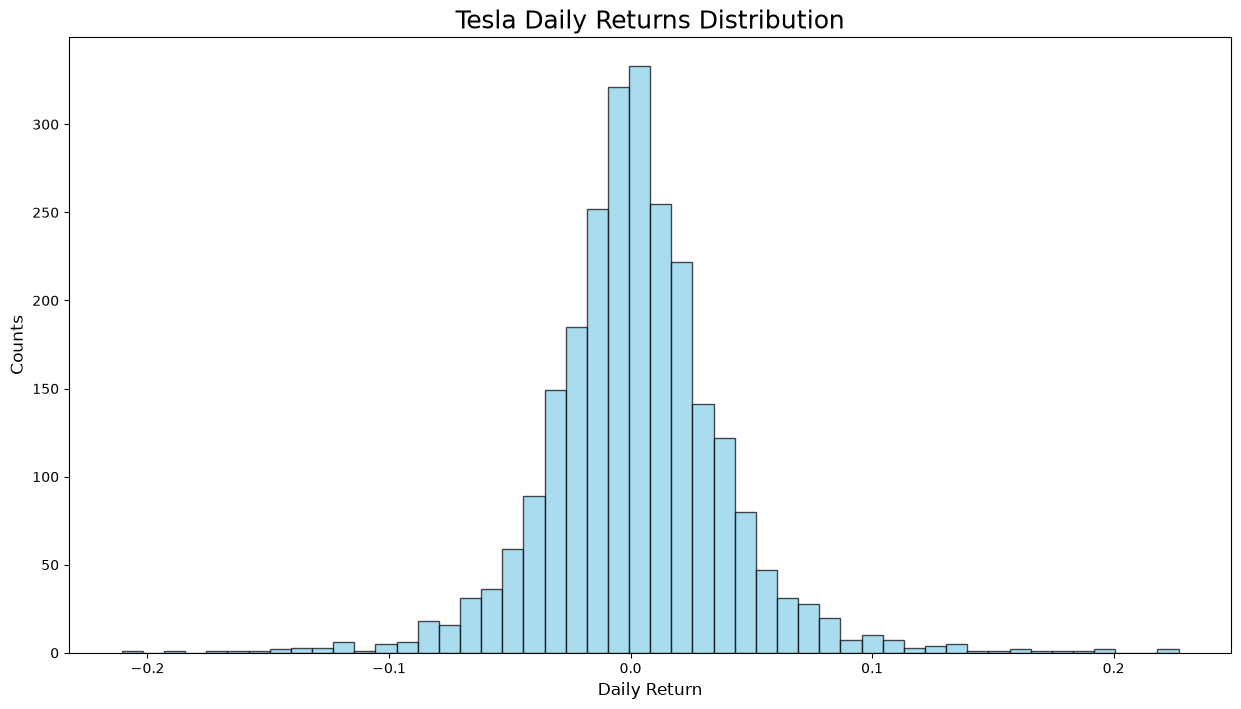

In [78]:
plt.figure(figsize=(15, 8))
tesla_data['Daily Return'].hist(bins=50, color='skyblue', edgecolor='black', alpha=0.7, grid=False)
plt.xlabel('Daily Return', fontsize=12)
plt.ylabel('Counts', fontsize=12)
plt.title('Tesla Daily Returns Distribution', fontsize=18)
plt.savefig('../images/3.tesla_daily_return_distribution.png', bbox_inches='tight')
plt.show()

In [79]:
# calculates the daily price gap
tesla_data['Price Gap'] = tesla_data['High'] - tesla_data['Low']

In [80]:
columns = ['Open', 'Close', 'Volume', 'High', 'Low', 'Daily Return', 'Price Gap']
correlation_matrix = tesla_data[columns].corr()
correlation_matrix['Close']

Open            0.998848
Close           1.000000
Volume         -0.336823
High            0.999497
Low             0.999530
Daily Return    0.004618
Price Gap       0.772348
Name: Close, dtype: float64

**Feature selection for training**

In [81]:
df = tesla_data[["Close", "Open", "High", "Low"]]


## Strategy based data split

In [82]:
# train-validation-test split on data (70% - 15% - 15%)
train_end = int(0.7 * len(df))
validation_end = int(0.85 * len(df))

In [83]:
seq_length = 60

In [84]:
train_data = df.iloc[:train_end].values
val_data = df.iloc[train_end - seq_length : validation_end].values
test_data = df.iloc[validation_end - seq_length :].values

In [85]:
# feature Scaling
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_data)
test_scaled = scaler.transform(test_data)
validation_scaled = scaler.transform(val_data)

In [86]:
# sequence creation function
def create_sequences(data, seq_length):
    sequences, labels = [], []
    for i in range(len(data) - seq_length):
        sequences.append(data[i:i+seq_length])
        labels.append(data[i+seq_length, 0]) # predicting 'Close' price
    return np.array(sequences), np.array(labels)

In [87]:
X_train, y_train = create_sequences(train_scaled, seq_length)
X_test, y_test = create_sequences(test_scaled, seq_length)
X_val, y_val = create_sequences(validation_scaled, seq_length)

**Dataset object to convert numpy array to tensor**

In [88]:
class TimeSeriesDataset(Dataset):
    def __init__(self, X, Y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.Y = torch.tensor(Y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.Y[index]

train_dataset = TimeSeriesDataset(X_train, y_train)
val_dataset = TimeSeriesDataset(X_val, y_val)
test_dataset = TimeSeriesDataset(X_test, y_test)


In [89]:
batch_size=32

In [90]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## LSTM Model

In [91]:
class LSTMModel(nn.Module):
    def __init__(self, input_dim):
        super(LSTMModel, self).__init__()

        # Lstm layer
        self.lstm1 = nn.LSTM(input_dim, 128, batch_first=True)
        self.drop1 = nn.Dropout(0.2)
        self.lstm2 = nn.LSTM(128, 128, batch_first=True)
        self.drop2 = nn.Dropout(0.2)
        self.lstm3 = nn.LSTM(128, 64, batch_first=True)

        # Dense layer
        self.model = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        x, _ = self.lstm1(x)
        x = self.drop1(x)
        x, _ = self.lstm2(x)
        x = self.drop2(x)
        x, _ = self.lstm3(x)

        x = x[:, -1, :] # get the last time step data for the dense layer.

        return self.model(x)


**Model Creation**

In [92]:
from torchinfo import summary

model = LSTMModel(input_dim=X_train.shape[2]).to(device)
summary(model, input_size=(32, X_train.shape[1], X_train.shape[2]))

Layer (type:depth-idx)                   Output Shape              Param #
LSTMModel                                [32, 1]                   --
├─LSTM: 1-1                              [32, 60, 128]             68,608
├─Dropout: 1-2                           [32, 60, 128]             --
├─LSTM: 1-3                              [32, 60, 128]             132,096
├─Dropout: 1-4                           [32, 60, 128]             --
├─LSTM: 1-5                              [32, 60, 64]              49,664
├─Sequential: 1-6                        [32, 1]                   --
│    └─Linear: 2-1                       [32, 32]                  2,080
│    └─ReLU: 2-2                         [32, 32]                  --
│    └─Linear: 2-3                       [32, 1]                   33
Total params: 252,481
Trainable params: 252,481
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 480.77
Input size (MB): 0.03
Forward/backward pass size (MB): 4.92
Params size (MB): 1.01
Estimated To

In [93]:
learning_rate = 0.001
epochs = 200
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=0.0001)

In [94]:
total_training_loss = []
total_validation_loss = []

for epoch in range(epochs):
    # training
    model.train()
    total_train_loss = 0
    train_samples = 0

    for inputs, labels in train_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        batch_size = labels.size(0)

        optimizer.zero_grad()
        prediction = model(inputs).squeeze(1)
        loss = criterion(prediction, labels)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * batch_size
        train_samples += batch_size

    # validation
    model.eval()
    total_val_loss = 0
    val_samples = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            batch_size = labels.size(0)

            prediction = model(inputs).squeeze(1)
            loss = criterion(prediction, labels)

            total_val_loss += loss.item() * batch_size
            val_samples += batch_size

    # metrics
    train_loss = total_train_loss / train_samples
    val_loss = total_val_loss / val_samples

    total_training_loss.append(train_loss)
    total_validation_loss.append(val_loss)

    if (epoch + 1) % 10 == 0:
        print(f"| Epoch: {epoch + 1} | Train Loss: {train_loss:.4f} | Validation Loss: {val_loss:.4f} |")
        print("-" * 60)

| Epoch: 10 | Train Loss: 0.0014 | Validation Loss: 0.0056 |
------------------------------------------------------------
| Epoch: 20 | Train Loss: 0.0015 | Validation Loss: 0.0046 |
------------------------------------------------------------
| Epoch: 30 | Train Loss: 0.0009 | Validation Loss: 0.0036 |
------------------------------------------------------------
| Epoch: 40 | Train Loss: 0.0009 | Validation Loss: 0.0023 |
------------------------------------------------------------
| Epoch: 50 | Train Loss: 0.0009 | Validation Loss: 0.0038 |
------------------------------------------------------------
| Epoch: 60 | Train Loss: 0.0009 | Validation Loss: 0.0024 |
------------------------------------------------------------
| Epoch: 70 | Train Loss: 0.0008 | Validation Loss: 0.0019 |
------------------------------------------------------------
| Epoch: 80 | Train Loss: 0.0009 | Validation Loss: 0.0020 |
------------------------------------------------------------
| Epoch: 90 | Train Loss

In [95]:
model.eval()
total_test_loss = 0
test_samples = 0

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        batch_size = labels.size(0)

        prediction = model(inputs).squeeze(1)
        loss = criterion(prediction, labels)

        total_test_loss += loss.item() * batch_size
        test_samples += batch_size

test_loss = total_test_loss / test_samples

print("-" * 21)
print(f"| Test Loss: {test_loss:.4f} |")
print("-" * 21)

---------------------
| Test Loss: 0.0040 |
---------------------


In [96]:
# generate predictions on the test dataset
model.eval()
test_preds = []
test_targets = []

with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = model(inputs).squeeze(1)
        test_preds.extend(outputs.numpy())
        test_targets.extend(labels.numpy())


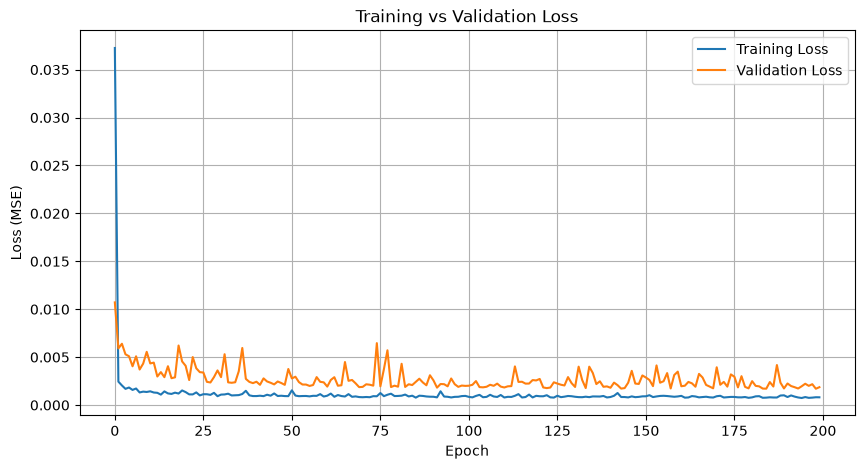

In [97]:
def plot_training_loss():
    plt.figure(figsize=(10, 5))
    plt.plot(total_training_loss, label="Training Loss")
    plt.plot(total_validation_loss, label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss (MSE)")
    plt.title("Training vs Validation Loss")
    plt.legend()
    plt.grid(True)
    plt.savefig('../images/4.training_vs_validation_loss.png', bbox_inches='tight')
    plt.show()

plot_training_loss()


In [ ]:
# convert predictions and actual targets into 1D arrays
y_pred = np.array(test_preds).flatten()
y_test = np.array(test_targets).flatten()

# add three zero columns so the scaler receives all four features
y_pred_full = np.column_stack([y_pred, np.zeros((len(y_pred), 3))])
y_test_full = np.column_stack([y_test, np.zeros((len(y_test), 3))])

# reverse MinMax scaling to get actual closing prices
y_pred_actual = scaler.inverse_transform(y_pred_full)[:, 0]
y_test_actual = scaler.inverse_transform(y_test_full)[:, 0]

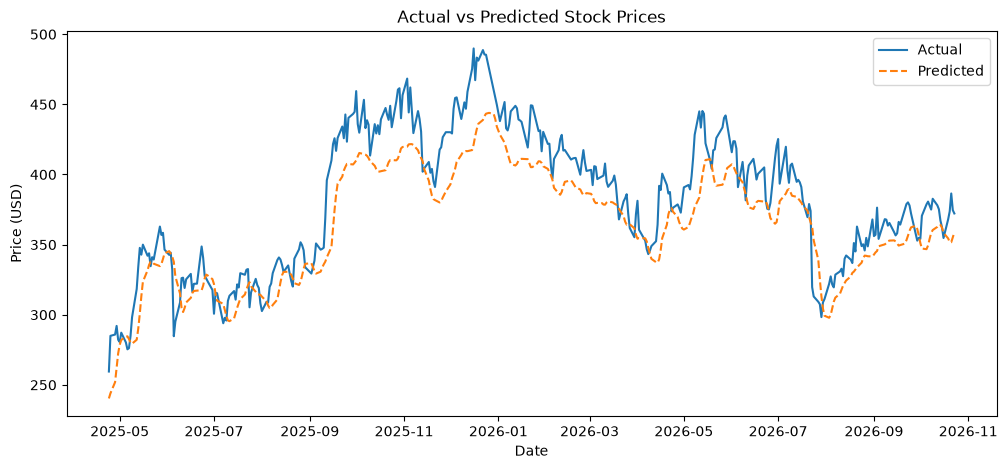

In [99]:
# get dates for the test predictions
test_dates = df.index[validation_end:]

# plot actual vs predicted prices
plt.figure(figsize=(12, 5))
plt.plot(test_dates, y_test_actual, label="Actual")
plt.plot(test_dates, y_pred_actual, "--", label="Predicted")
plt.title("Actual vs Predicted Stock Prices")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.savefig('../images/5.actual_va_predicted_stock_prices.png', bbox_inches='tight')
plt.show()

In [100]:
mae = mean_absolute_error(y_test_actual, y_pred_actual)
rmse = root_mean_squared_error(y_test_actual, y_pred_actual)
r2 = r2_score(y_test_actual, y_pred_actual) * 100
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.2f}%")

MAE:  20.6625
RMSE: 25.1258
R²:   74.31%


In [101]:
import joblib
torch.save(model.state_dict(), "../models/lstm_model.pth")
joblib.dump(scaler, "../models/scaler.pkl")

['../models/scaler.pkl']

In [102]:

# Load model
model = LSTMModel(input_dim=X_test.shape[2]).to(device)
model.load_state_dict(
    torch.load("../models/lstm_model.pth", map_location=device)
)
model.eval()

# Take one test sample
sample = torch.tensor(X_test[0:1], dtype=torch.float32).to(device)

# Predict scaled price
with torch.no_grad():
    prediction = model(sample).item()

# Convert to original stock prices
prediction_full = np.array([[prediction, 0, 0, 0]])
actual_full = np.array([[y_test[0], 0, 0, 0]])

predicted_price = scaler.inverse_transform(prediction_full)[0, 0]
actual_price = scaler.inverse_transform(actual_full)[0, 0]

# Display results
print("Predicted Stock Price:", predicted_price)
print("Actual Stock Price:", actual_price)


Predicted Stock Price: 240.32256260063713
Actual Stock Price: 259.5100000791316
